### Import libraries:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

### Load the dataset:

In [2]:
df_api_performance = pd.read_csv("../data/api_performance.csv")

### Explore the dataset:

In [3]:
df_api_performance.head()

,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy


In [4]:
df_api_performance.shape

(6, 13)

In [5]:
df_api_performance.columns

Index(['endpoint', 'total_api_records', 'total_users', 'total_requests',
       'successful_requests', 'failed_requests', 'error_rate_percentage',
       'success_rate_percentage', 'average_response_time_ms',
       'maximum_response_time_ms', 'error_rate_rank', 'response_time_rank',
       'api_health_status'],
      dtype='str')

In [6]:
df_api_performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   endpoint                  6 non-null      str    
 1   total_api_records         6 non-null      int64  
 2   total_users               6 non-null      int64  
 3   total_requests            6 non-null      int64  
 4   successful_requests       6 non-null      int64  
 5   failed_requests           6 non-null      int64  
 6   error_rate_percentage     6 non-null      float64
 7   success_rate_percentage   6 non-null      float64
 8   average_response_time_ms  6 non-null      float64
 9   maximum_response_time_ms  6 non-null      float64
 10  error_rate_rank           6 non-null      int64  
 11  response_time_rank        6 non-null      int64  
 12  api_health_status         6 non-null      str    
dtypes: float64(4), int64(7), str(2)
memory usage: 916.0 bytes


In [7]:
df_api_performance.describe().T

,count,mean,std,min,25%,50%,75%,max
total_api_records,6.0,8.333333e+03,72.090684,8222.00,8.302250e+03,8334.00,8375.500,8429.00
total_users,6.0,5.641333e+03,28.296054,5604.00,5.630000e+03,5639.50,5646.000,5690.00
total_requests,6.0,4.205114e+06,49060.212146,4129971.00,4.173754e+06,4221663.00,4243103.250,4249354.00
successful_requests,6.0,3.994905e+06,47128.351091,3923105.00,3.964447e+06,4010683.50,4031686.000,4037237.00
failed_requests,6.0,2.102090e+05,2000.111797,206866.00,2.093065e+05,210697.00,211699.750,212117.00
error_rate_percentage,6.0,4.998333e+00,0.018348,4.97,4.990000e+00,5.00,5.010,5.02
success_rate_percentage,6.0,9.500167e+01,0.018348,94.98,9.499000e+01,95.00,95.010,95.03
average_response_time_ms,6.0,5.104233e+02,2.637534,506.25,5.093575e+02,510.63,511.820,513.88
maximum_response_time_ms,6.0,9.998533e+02,0.142220,999.61,9.997900e+02,999.91,999.955,999.97
error_rate_rank,6.0,2.500000e+00,1.048809,1.00,2.000000e+00,2.50,3.000,4.00


### Identify available API metrics:

In [8]:
for column in df_api_performance.columns:
    print(column)

endpoint
total_api_records
total_users
total_requests
successful_requests
failed_requests
error_rate_percentage
success_rate_percentage
average_response_time_ms
maximum_response_time_ms
error_rate_rank
response_time_rank
api_health_status


### Analyze total API requests:

In [9]:
if "total_requests" in df_api_performance.columns:

    request_ranking = df_api_performance.sort_values(
        by="total_requests",
        ascending=False
    )

    display(request_ranking)

,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
5,/api/v1/users,8429,5690,4246916,4035640,211276,4.97,95.03,512.20,999.88,4,2,Healthy
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement


#### Visualize:

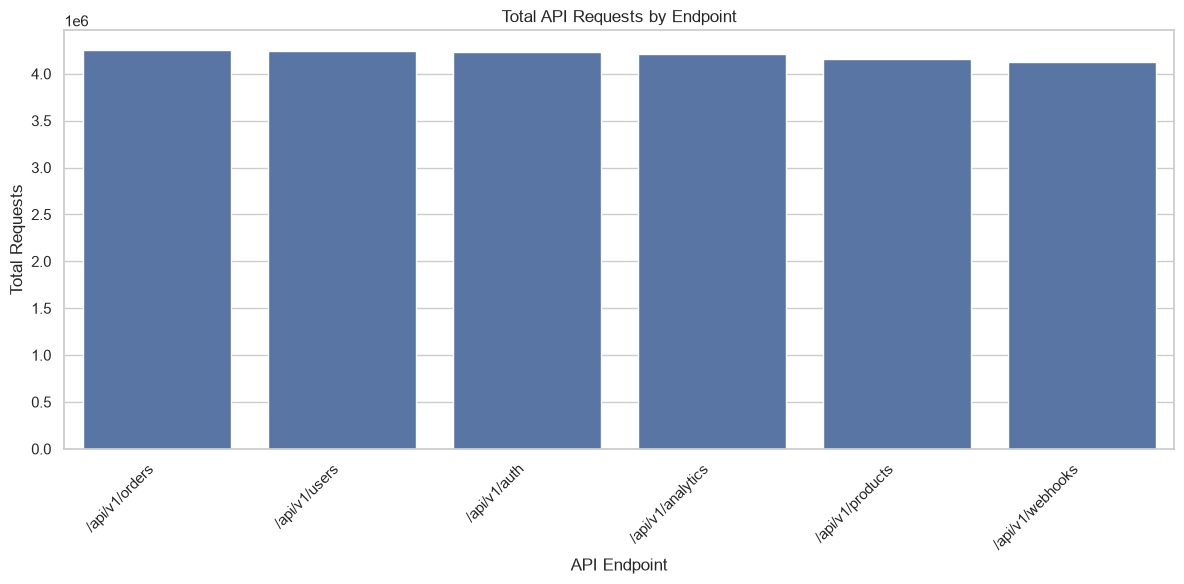

In [10]:
if "total_requests" in df_api_performance.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=df_api_performance.sort_values(
            "total_requests",
            ascending=False
        ),
        x="endpoint",
        y="total_requests"
    )

    plt.title("Total API Requests by Endpoint")
    plt.xlabel("API Endpoint")
    plt.ylabel("Total Requests")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

### Analyze API response time:

In [11]:
if "average_response_time_ms" in df_api_performance.columns:

    response_ranking = df_api_performance.sort_values(
        by="average_response_time_ms",
        ascending=False
    )

    display(response_ranking)

,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy
5,/api/v1/users,8429,5690,4246916,4035640,211276,4.97,95.03,512.20,999.88,4,2,Healthy
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement


#### Visualize:

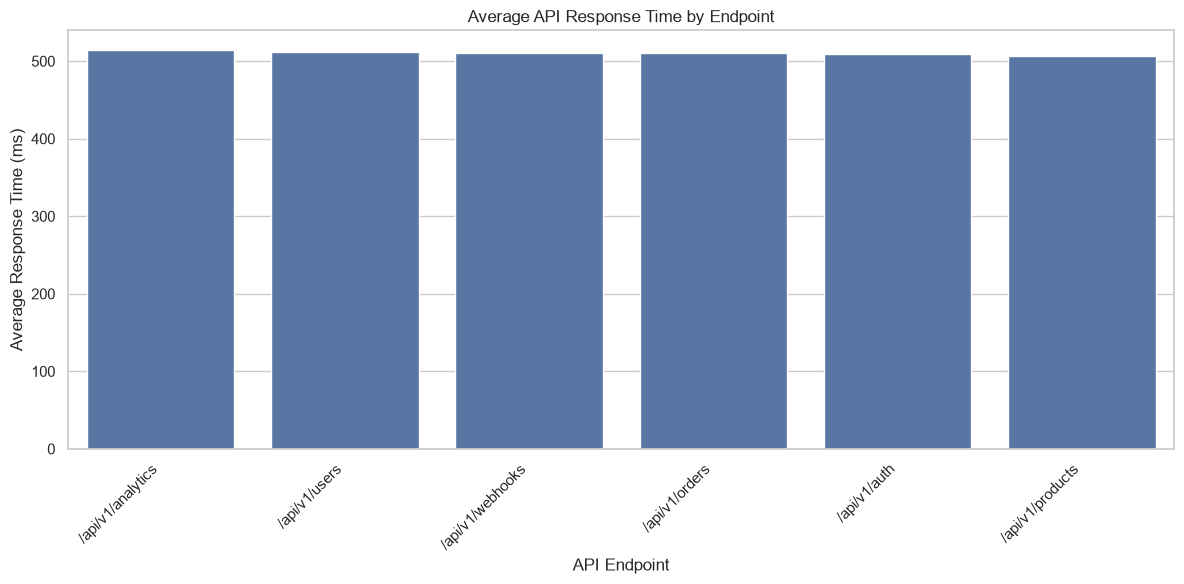

In [12]:
if "average_response_time_ms" in df_api_performance.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=df_api_performance.sort_values(
            "average_response_time_ms",
            ascending=False
        ),
        x="endpoint",
        y="average_response_time_ms"
    )

    plt.title("Average API Response Time by Endpoint")
    plt.xlabel("API Endpoint")
    plt.ylabel("Average Response Time (ms)")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

### Analyze API error rates:

In [13]:
if "error_rate_percentage" in df_api_performance.columns:

    error_ranking = df_api_performance.sort_values(
        by="error_rate_percentage",
        ascending=False
    )

    display(error_ranking)

,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy
5,/api/v1/users,8429,5690,4246916,4035640,211276,4.97,95.03,512.20,999.88,4,2,Healthy


#### Visualize:

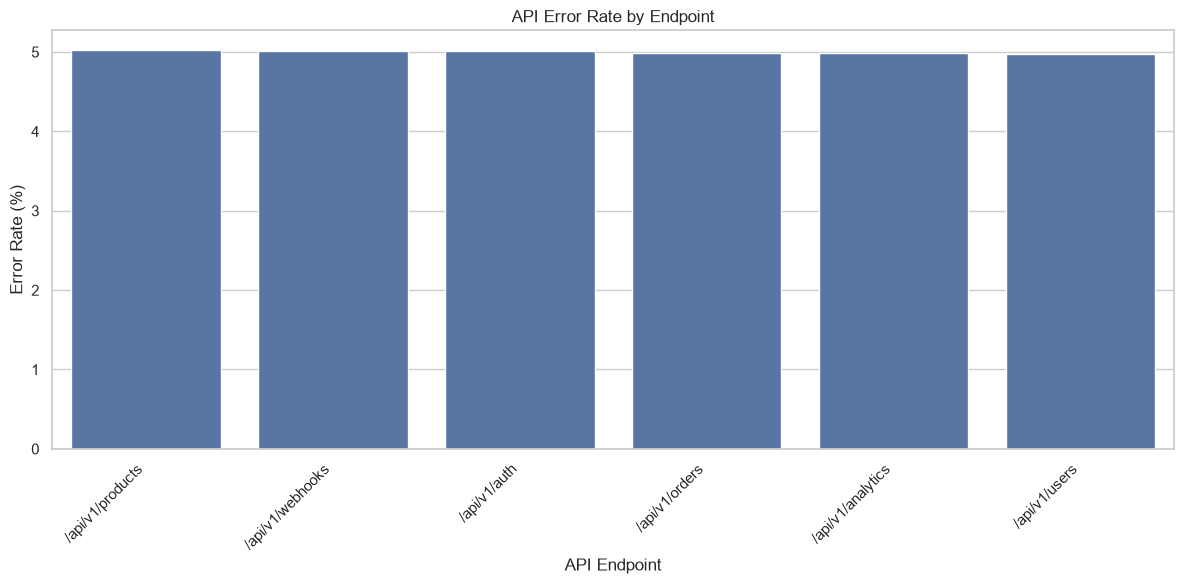

In [14]:
if "error_rate_percentage" in df_api_performance.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=df_api_performance.sort_values(
            "error_rate_percentage",
            ascending=False
        ),
        x="endpoint",
        y="error_rate_percentage"
    )

    plt.title("API Error Rate by Endpoint")
    plt.xlabel("API Endpoint")
    plt.ylabel("Error Rate (%)")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

### Compare successful and failed requests:

#### If both columns exist:

In [15]:
request_comparison = df_api_performance[
    ["endpoint", "successful_requests", "failed_requests"]
]

display(request_comparison)

,endpoint,successful_requests,failed_requests
0,/api/v1/products,3952082,209036
1,/api/v1/webhooks,3923105,206866
2,/api/v1/auth,4019824,211841
3,/api/v1/orders,4037237,212117
4,/api/v1/analytics,4001543,210118
5,/api/v1/users,4035640,211276


#### Create a grouped bar chart:

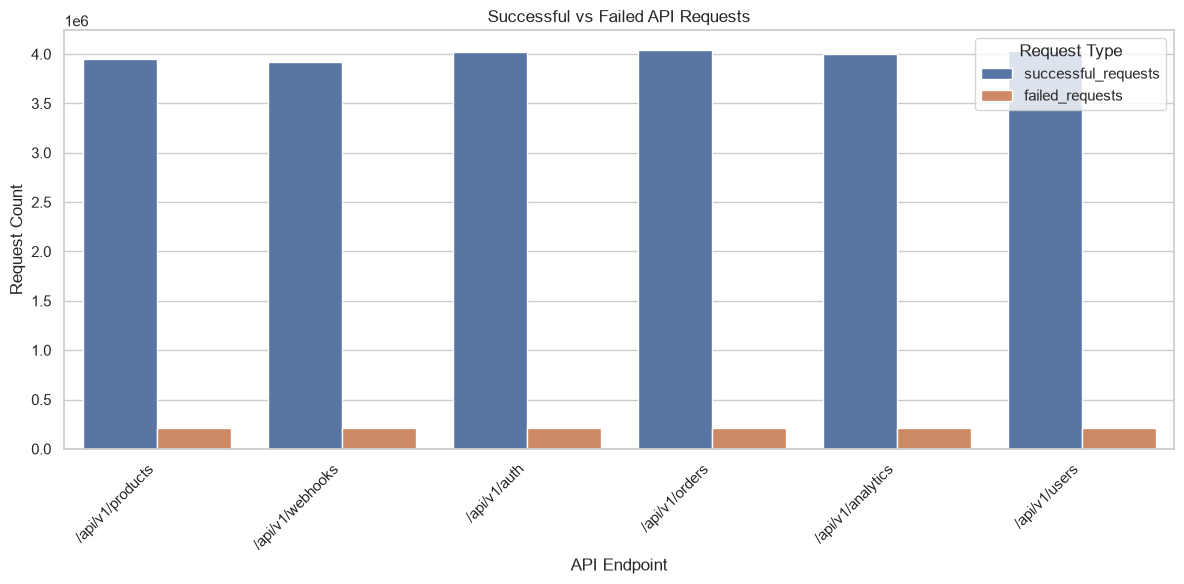

In [16]:
if all(
    col in df_api_performance.columns
    for col in ["successful_requests", "failed_requests"]
):

    comparison = df_api_performance.melt(
        id_vars="endpoint",
        value_vars=[
            "successful_requests",
            "failed_requests"
        ],
        var_name="Request Type",
        value_name="Request Count"
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=comparison,
        x="endpoint",
        y="Request Count",
        hue="Request Type"
    )

    plt.title("Successful vs Failed API Requests")
    plt.xlabel("API Endpoint")
    plt.ylabel("Request Count")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

### Analyze the relationship between response time and error rate:

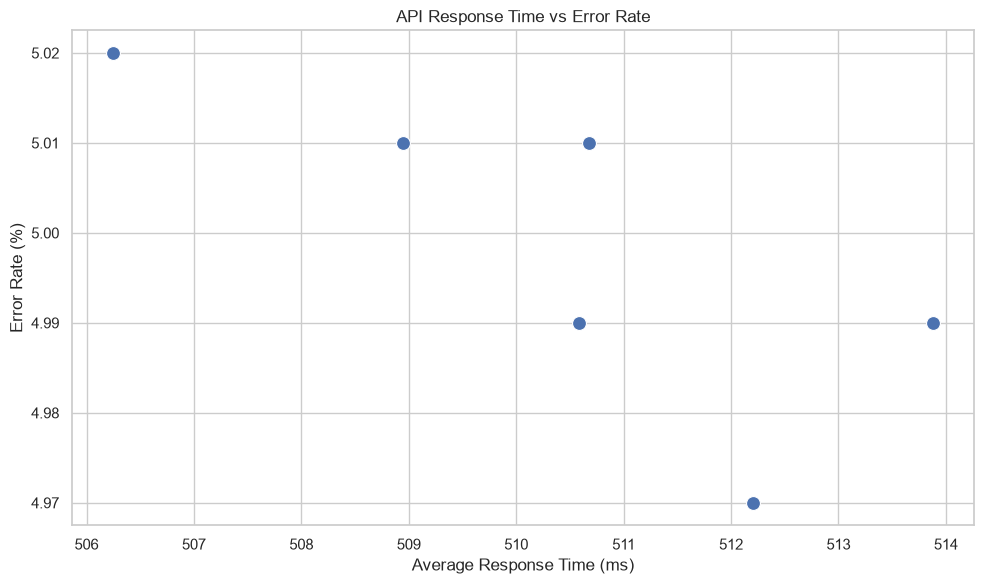

In [17]:
required_columns = [
    "average_response_time_ms",
    "error_rate_percentage"
]

if all(col in df_api_performance.columns for col in required_columns):

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=df_api_performance,
        x="average_response_time_ms",
        y="error_rate_percentage",
        s=100
    )

    plt.title("API Response Time vs Error Rate")
    plt.xlabel("Average Response Time (ms)")
    plt.ylabel("Error Rate (%)")

    plt.tight_layout()
    plt.show()

### Save reports and visualizations:

In [18]:
os.makedirs("../data", exist_ok=True)
os.makedirs("../visualizations", exist_ok=True)

#### Save the complete API performance dataset:

In [19]:
df_api_performance.to_csv(
    "../data/api_performance_eda_report.csv",
    index=False
)

print("API performance report saved successfully.")

API performance report saved successfully.
